# Assignment 2 — Learning Strategy (MNIST)
**Nur Ilham Iskandar** · NIM 572104 · Magister Kecerdasan Artifisial, UGM
Course: Neural Network (Dr. Afiahayati)

1. Replication of the MNIST fully-connected classifier from the *Learning Strategy* slides (p. 14–23)
2. Experiments: (a) L1, (b) L2, (c) Dropout, (d) Early stopping, (e) L1 + Dropout

## Part 1 — Replication of the slides
### 1. Load data

In [1]:
import keras
from keras.datasets import mnist
keras.utils.set_random_seed(42)  # reproducibility

(X_train, y_train), (X_test, y_test) = mnist.load_data()
X_train = X_train.reshape(-1, 28,28,1)
X_test = X_test.reshape(-1, 28,28,1)
X_train = X_train.astype('float32')
X_test = X_test.astype('float32')
X_train /= 255
X_test /= 255
y_train = keras.utils.to_categorical(y_train, 10)
y_test = keras.utils.to_categorical(y_test, 10)

### 2. Define model

In [2]:
from keras.models import Sequential
from keras.layers import Flatten, Dense, Input

model1 = Sequential()
model1.add(Input(shape=(28,28,1)))   # newer Keras needs the input shape to print the summary before fit
model1.add(Flatten())
model1.add(Dense(64,activation='relu'))
model1.add(Dense(10,activation='softmax'))
model1.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        50,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 50,890 (198.79 KB)

 Trainable params: 50,890 (198.79 KB)

 Non-trainable params: 0 (0.00 B)

### 3. Compile, fit, save and evaluate

In [3]:
model1.compile(optimizer='adam',loss='categorical_crossentropy',metrics=['acc'])
history1 = model1.fit(X_train,y_train,epochs=10,batch_size=100,validation_data=(X_test,y_test))
model1.save('my_model1.h5')
model1.evaluate(X_test,y_test)

Epoch 1/10


  1/600 ━━━━━━━━━━━━━━━━━━━━ 8:53 891ms/step - acc: 0.0600 - loss: 2.3810

 25/600 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - acc: 0.5160 - loss: 1.6886    

 50/600 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - acc: 0.6626 - loss: 1.2529

 75/600 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - acc: 0.7236 - loss: 1.0256

...

219/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - acc: 0.9693 - loss: 0.1004

255/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - acc: 0.9719 - loss: 0.0915

291/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - acc: 0.9738 - loss: 0.0864

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - acc: 0.9727 - loss: 0.0887


[0.08874902874231339, 0.9726999998092651]

### 3. Visualize model evaluation

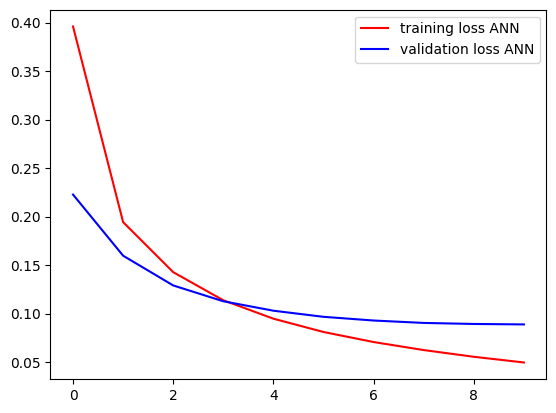

In [4]:
import matplotlib.pyplot as plt

epochs = range(10)
loss1 = history1.history['loss']
val_loss1 = history1.history['val_loss']
plt.plot(epochs,loss1,'r',label='training loss ANN')
plt.plot(epochs,val_loss1,'b',label='validation loss ANN')
plt.legend()
plt.show()

### 3. Load model and prediction

In [5]:
import numpy as np
from keras.models import load_model

model_simpan = load_model('my_model1.h5')
pred = model_simpan.predict(X_test)
print('label actual:',np.argmax(y_test[30]))
print('label prediction:',np.argmax(pred[30]))

  1/313 ━━━━━━━━━━━━━━━━━━━━ 11s 36ms/step

 49/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step  

 97/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step

145/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step

194/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step

241/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step

284/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


label actual: 3
label prediction: 3


## Part 2 — Experiments

**Setup shared by every scenario** (so results are comparable):
- Split as on slide 18: **55,000 train / 5,000 validation / 10,000 test**. The test set is never used during training, which matters for early stopping.
- Same architecture as Part 1 (784 → Dense 64 ReLU → Dense 10 softmax), Adam, batch 100, seed 42.
- **30 epochs** instead of 10, so overfitting has time to show up in the baseline.

**Chosen rates:** L1 = 0.0001 · L2 = 0.001 · Dropout = 0.3 · Early stopping on `val_loss`, patience 3, restore best weights.

In [6]:
from keras.layers import Dropout
from keras import regularizers
from keras.callbacks import EarlyStopping

X_tr, Y_tr = X_train[:55000], y_train[:55000]
X_val, Y_val = X_train[55000:], y_train[55000:]
EPOCHS, BATCH = 30, 100
L1_RATE, L2_RATE, DROP_RATE = 1e-4, 1e-3, 0.3
summary_table = {}

def build_model(l1=None, l2=None, dropout=None):
    reg = regularizers.l1(l1) if l1 else (regularizers.l2(l2) if l2 else None)
    m = Sequential()
    m.add(Input(shape=(28,28,1)))
    m.add(Flatten())
    m.add(Dense(64, activation='relu', kernel_regularizer=reg))
    if dropout:
        m.add(Dropout(dropout))
    m.add(Dense(10, activation='softmax', kernel_regularizer=reg))
    m.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['acc'])
    return m

def run(name, callbacks=None, **cfg):
    keras.utils.set_random_seed(42)
    m = build_model(**cfg)
    m.summary()
    h = m.fit(X_tr, Y_tr, epochs=EPOCHS, batch_size=BATCH,
              validation_data=(X_val, Y_val), callbacks=callbacks or [], verbose=0)
    tr_loss, tr_acc = m.evaluate(X_tr, Y_tr, verbose=0)
    te_loss, te_acc = m.evaluate(X_test, y_test, verbose=0)
    ce = keras.losses.CategoricalCrossentropy()
    te_ce = float(ce(y_test, m.predict(X_test, verbose=0)))   # loss WITHOUT the penalty term
    w = m.layers[1].get_weights()[0]
    zero = float((np.abs(w) < 1e-3).mean())
    best = int(np.argmin(h.history['val_loss'])) + 1
    print(f"Train acc {tr_acc:.4f} | Test acc {te_acc:.4f} | gap {tr_acc-te_acc:.4f}")
    print(f"Test loss (incl. penalty) {te_loss:.4f} | test cross-entropy {te_ce:.4f}")
    print(f"Epochs run {len(h.history['loss'])} | best val epoch {best} | weights |w|<1e-3: {zero:.1%}")
    summary_table[name] = dict(train_acc=tr_acc, test_acc=te_acc, gap=tr_acc-te_acc,
                               test_ce=te_ce, epochs=len(h.history['loss']), near_zero=zero)
    ep = range(1, len(h.history['loss'])+1)
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    ax[0].plot(ep, h.history['loss'], 'r', label='training loss')
    ax[0].plot(ep, h.history['val_loss'], 'b', label='validation loss')
    ax[0].set_title(f'{name} — loss'); ax[0].set_xlabel('epoch'); ax[0].legend()
    ax[1].plot(ep, h.history['acc'], 'r', label='training acc')
    ax[1].plot(ep, h.history['val_acc'], 'b', label='validation acc')
    ax[1].set_title(f'{name} — accuracy'); ax[1].set_xlabel('epoch'); ax[1].legend()
    plt.tight_layout(); plt.show()
    return m, h

### Baseline (no regularization, 30 epochs) — reference point

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │        50,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 50,890 (198.79 KB)

 Trainable params: 50,890 (198.79 KB)

 Non-trainable params: 0 (0.00 B)

Train acc 0.9974 | Test acc 0.9745 | gap 0.0229
Test loss (incl. penalty) 0.1116 | test cross-entropy 0.1105
Epochs run 30 | best val epoch 8 | weights |w|<1e-3: 0.5%


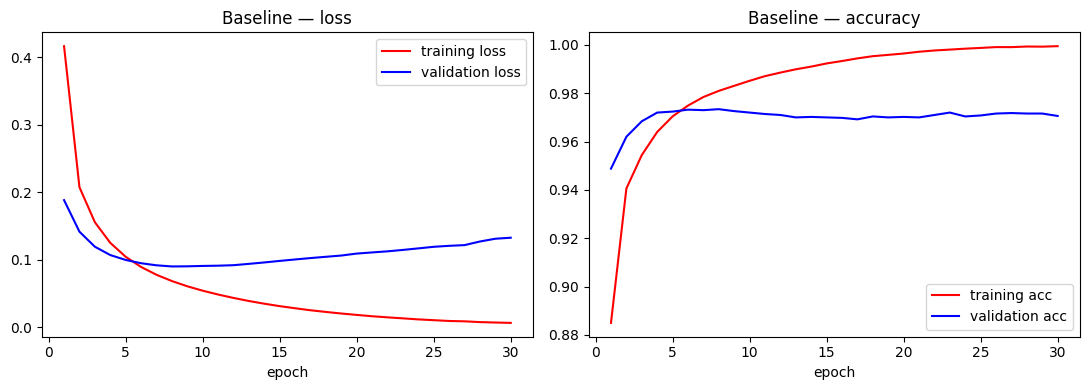

In [7]:
m0, h0 = run('Baseline')

### 2(a) L1 regularization — rate 0.0001

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_2 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │        50,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 50,890 (198.79 KB)

 Trainable params: 50,890 (198.79 KB)

 Non-trainable params: 0 (0.00 B)

Train acc 0.9860 | Test acc 0.9764 | gap 0.0096
Test loss (incl. penalty) 0.1736 | test cross-entropy 0.0766
Epochs run 30 | best val epoch 30 | weights |w|<1e-3: 55.1%


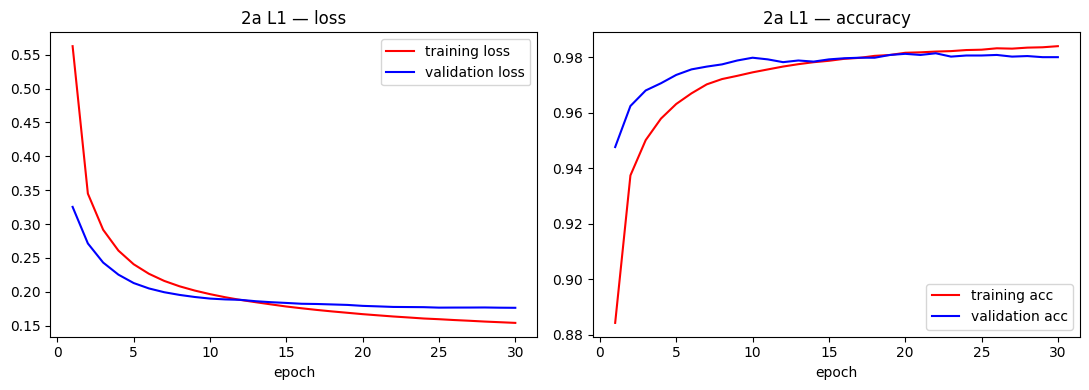

In [8]:
m_a, h_a = run('2a L1', l1=L1_RATE)

### 2(b) L2 regularization — rate 0.001

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_3 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 64)             │        50,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 50,890 (198.79 KB)

 Trainable params: 50,890 (198.79 KB)

 Non-trainable params: 0 (0.00 B)

Train acc 0.9742 | Test acc 0.9698 | gap 0.0044
Test loss (incl. penalty) 0.2367 | test cross-entropy 0.1140
Epochs run 30 | best val epoch 30 | weights |w|<1e-3: 27.8%


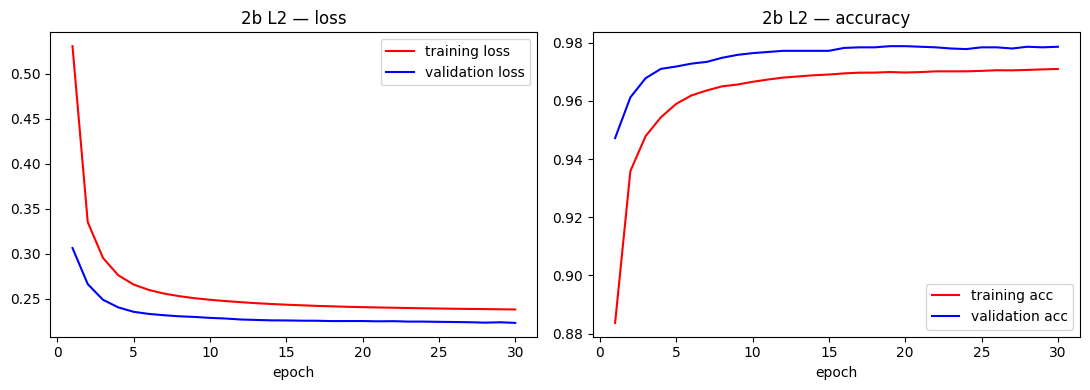

In [9]:
m_b, h_b = run('2b L2', l2=L2_RATE)

### 2(c) Dropout — rate 0.3

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_4 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 64)             │        50,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 50,890 (198.79 KB)

 Trainable params: 50,890 (198.79 KB)

 Non-trainable params: 0 (0.00 B)

Train acc 0.9924 | Test acc 0.9746 | gap 0.0178
Test loss (incl. penalty) 0.0915 | test cross-entropy 0.0915
Epochs run 30 | best val epoch 16 | weights |w|<1e-3: 0.5%


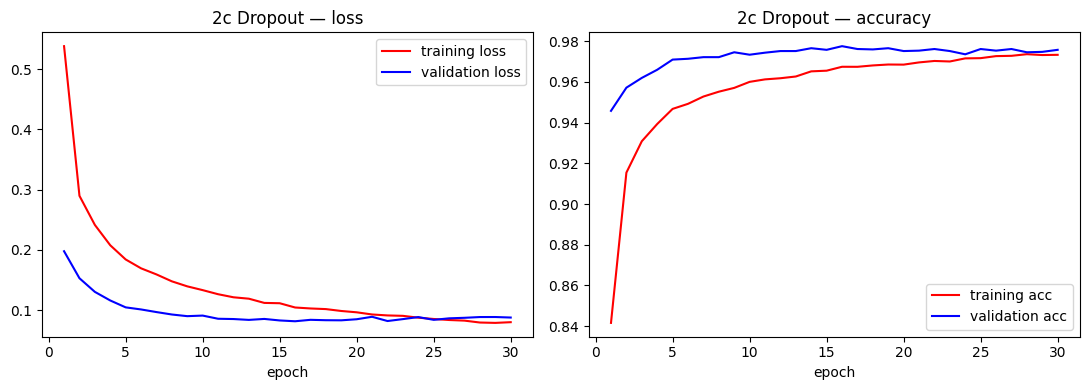

In [10]:
m_c, h_c = run('2c Dropout', dropout=DROP_RATE)

### 2(d) Early stopping — monitor val_loss, patience 3, restore best weights

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_5 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 64)             │        50,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 50,890 (198.79 KB)

 Trainable params: 50,890 (198.79 KB)

 Non-trainable params: 0 (0.00 B)

Train acc 0.9828 | Test acc 0.9724 | gap 0.0104
Test loss (incl. penalty) 0.0965 | test cross-entropy 0.0965
Epochs run 11 | best val epoch 8 | weights |w|<1e-3: 0.8%


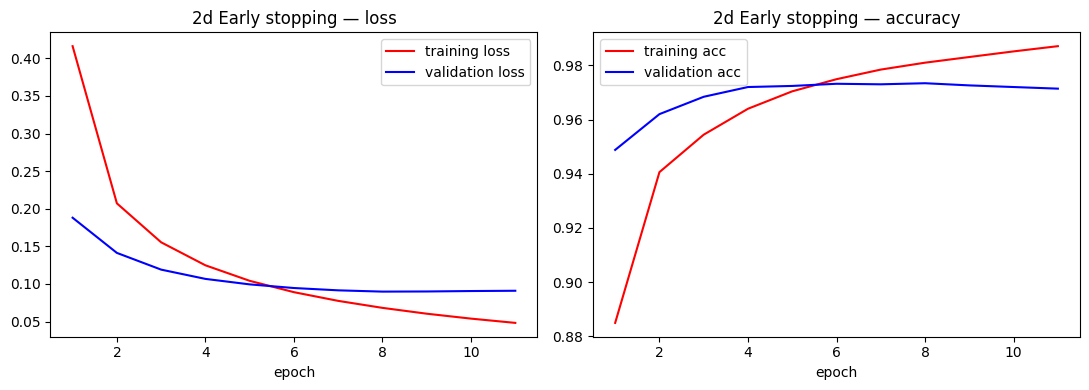

In [11]:
es = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)
m_d, h_d = run('2d Early stopping', callbacks=[es])

### 2(e) L1 (0.0001) + Dropout (0.3)

Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_6 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 64)             │        50,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 50,890 (198.79 KB)

 Trainable params: 50,890 (198.79 KB)

 Non-trainable params: 0 (0.00 B)

Train acc 0.9809 | Test acc 0.9739 | gap 0.0070
Test loss (incl. penalty) 0.2093 | test cross-entropy 0.0874
Epochs run 30 | best val epoch 29 | weights |w|<1e-3: 44.1%


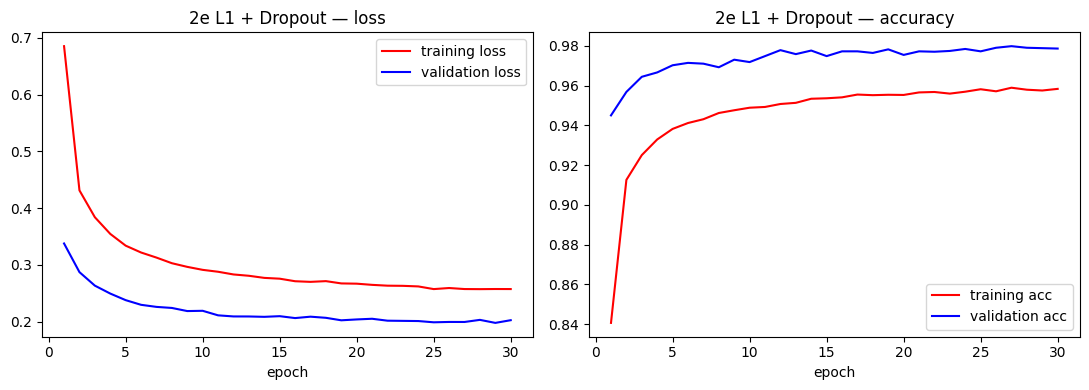

In [12]:
m_e, h_e = run('2e L1 + Dropout', l1=L1_RATE, dropout=DROP_RATE)

### Comparison

In [13]:
import pandas as pd
pd.DataFrame(summary_table).T.round(4)

,train_acc,test_acc,gap,test_ce,epochs,near_zero
Baseline,0.9974,0.9745,0.0229,0.1105,30.0,0.0045
2a L1,0.9860,0.9764,0.0096,0.0766,30.0,0.5505
2b L2,0.9742,0.9698,0.0044,0.1140,30.0,0.2778
2c Dropout,0.9924,0.9746,0.0178,0.0915,30.0,0.0053
2d Early stopping,0.9828,0.9724,0.0104,0.0965,11.0,0.0075
2e L1 + Dropout,0.9809,0.9739,0.0070,0.0874,30.0,0.4413
